# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 6</span>


In Statistical Mechanics the one-dimensional (1D) Ising Model is exactly resoluble. The Hamiltonian for a system of N spins with nearest neighbors interaction is given by (in the following I will assume units such that $\mu_B=1$ and $k_B=1$):

$$
H = 
-J\sum_{i=1}^N s_i s_{i+1}
-\frac{h}{2}\sum_{i=1}^N (s_i + s_{i+1}) 
$$

where $\{ s_i \}_{i=1,N}$ are spin variables taking values in $\{-1;1\}$, $J>0$ (ferromagnetic model),and with the assumption $s_{N+1} = s_{1}$.

The partition function for $N$ spins, $Z$, can be exactly computed and it turns out to be:

$$
Z=\sum_{\{ s_i \}} \exp \left( -\beta H\right) = \lambda_1^N + \lambda_2^N
$$

where
$\lambda_{1,2} = 
e^{\beta J} 
\cosh (\beta h) \pm \left[ e^{2\beta J} \cosh^2 (\beta h) - 2\sinh (2\beta J) \right]^{1/2}$, 
and where $\beta=\frac{1}{k_b T} = \frac{1}{T}$.
Once the partition function has been computed, the Helmholtz free energy is readly obtained as $A = -k_B T \ln Z$. All the thermodynamic quantities of interest can be deduced from $A$ or, equivalently, from $Z$:

- the **Internal Energy** per spin (with $h=0$):

$$
\frac{U(N,T)}{N} = \frac{\langle H \rangle}{N}
= \frac{1}{N} \sum_{\{ s_i \}} H \frac{\exp \left( -\beta H\right)}{Z}
= -\frac{1}{N}\frac{\partial \ln Z}{\partial \beta}
\underset{h=0}= -J \tanh (\beta J) \Biggl( \frac{1 + \tanh^{N-2} (\beta J)}{1+\tanh^N (\beta J)} \Biggl)
$$

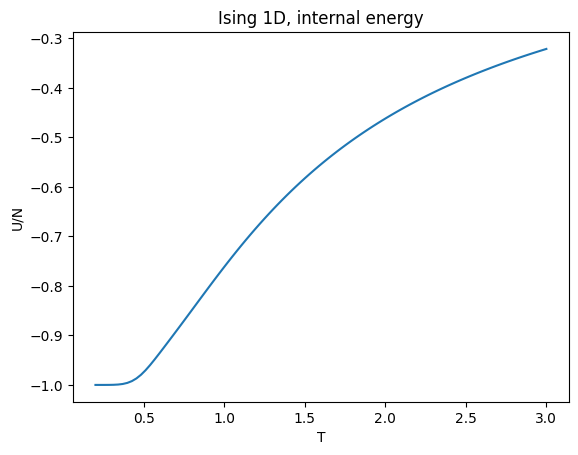

In [1]:
import numpy as np
import matplotlib.pyplot as plt
points=100
T = np.linspace(0.2,3.0,num=points)
beta = 1/T
J = 1.0
Ns = 50
th = np.tanh(J/T)
thN= th**Ns
ch = 1/th
e = -J*( th + ch*thN )/( 1 + thN )
plt.plot(T, e)
plt.title('Ising 1D, internal energy')
plt.xlabel('T')
plt.ylabel('U/N')
plt.show()

Da -1 perchè J=1 e per la temperatura che va a 0 gli spin saranno tutti allineati e quindi il termine dell'hamiltoniana in J è 1.


- the **Heat Capacity** (with $h=0$):

$$
C(N,T) = \frac{\partial U(N,T)}{\partial T}
= \frac{\partial \beta}{\partial T}\frac{\partial U}{\partial \beta}
= -k_B\beta^2 \frac{\partial}{\partial \beta} \left[ \sum_{\{ s_i \}} H \frac{\exp \left( -\beta H\right)}{Z} \right] = \\
= -k_B\beta^2 \left[ -\sum_{\{ s_i \}} H^2 \frac{\exp \left( -\beta H\right)}{Z} + \sum_{\{ s_i \}} H \exp \left( -\beta H\right)\frac{\partial Z^{-1}}{\partial \beta} \right] = \\
= k_B\beta^2 \left\{ \sum_{\{ s_i \}} H^2 \frac{\exp \left( -\beta H\right)}{Z} + \left[ \sum_{\{ s_i \}} H \frac{\exp \left( -\beta H\right)}{Z}\right]\frac{1}{Z}\frac{\partial Z}{\partial \beta} \right\} =\\
= k_B\beta^2 \left\{ \sum_{\{ s_i \}} H^2 \frac{\exp \left( -\beta H\right)}{Z} - \left[ \sum_{\{ s_i \}} H \frac{\exp \left( -\beta H\right)}{Z}\right]^2 \right\} =
k_B\beta^2 \left(\langle H^2 \rangle -\langle H \rangle^2 \right)
$$

$$
\frac{C(N,T)}{N} = \frac{1}{N}\frac{\partial U(N,T)}{\partial T} =\\
\underset{h=0}= 
k_B (\beta J)^2 \left\{ 1+\tanh^N (\beta J)+(N-1)\tanh^2 (\beta J)+(N-1)\frac{\tanh^{N-2} (\beta J)}{1+\tanh^N (\beta J)}
- N \left[ \frac{\tanh (\beta J) + \tanh^{N-1} (\beta J)}{1+\tanh^N (\beta J)} \right]^2 \right\}
$$

Le funzioni di risposta sono fluttuazioni di altre grandezze termodinamiche, per esempio il calore specifico misura le fluttuazioni quadratiche dell'energia.

la quantità da calcolare è una varianza che deve entrare nel data blocking, dobbiamo calcolare la variazione di una variazione.

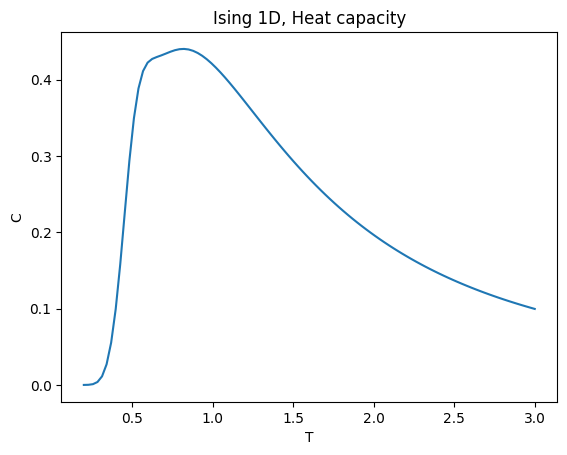

In [2]:
heat=((beta*J)**2)*(((1+thN+(Ns-1)*(th**2)+(Ns-1)*(ch**2)*thN)/(1+thN))-Ns*((th+ch*thN)/(1+thN))**2)
plt.plot(T, heat)
plt.title('Ising 1D, Heat capacity')
plt.xlabel('T')
plt.ylabel('C')
plt.show()

Il picco rappresenta un tentativo di transizione di fase che però viene abortito, la magnetizzazione non è spontantea e avviene solo a temperatura T=0. non si vedono discontinuità tipiche delle transizioni di fase; questo perchè siamo in 1D in 2D avviene una transizione di fase.

- The **magnetization** (with $h \not= 0$):

Note that with $h=0$ the magnetization $M(N,T,h=0)=\langle \sum_{i=1,N}s_i \rangle =0$ because in 1D we cannot have a (ferromagnetic) phase transition in absence of an external magnetic field.

$$
M(N,T,h) = -\frac{\partial A}{\partial h} = k_B T \frac{\partial \ln Z}{\partial h} =
\frac{1}{\beta} \frac{1}{Z}\frac{\partial}{\partial h}\sum_{\{ s_i \}} \exp \left( -\beta H\right) = \sum_{\{ s_i \}} \left[ \sum_{i=1,N}s_i\right] \frac{\exp \left( -\beta H\right)}{Z} = \left\langle \sum_{i=1,N}s_i \right\rangle
$$

The exact formula from $M(N,T,h) = k_B T \dfrac{\partial \ln Z}{\partial h}$ is:
$$
\frac{M(N,T,h)}{N}=\frac{e^{\beta J}\; \sinh(\beta h)}{Z} \; \Bigl[\lambda_1^{N-1}\cdot \Bigl(1+\frac{e^{\beta J}\; \cosh(\beta h)}{\sqrt{e^{2\beta J} \cosh^2 (\beta h) - 2\sinh (2\beta J)}}\Bigr) + \lambda_2^{N-1}\cdot \Bigl(1-\frac{e^{\beta J}\; \cosh(\beta h)}{\sqrt{e^{2\beta J} \cosh^2 (\beta h) - 2\sinh (2\beta J)}}\Bigr)\Bigr]
$$

La magnetizzazione è data dalla presenza del campo esterno che forza gli spin ad avere una direzione privilegiata.

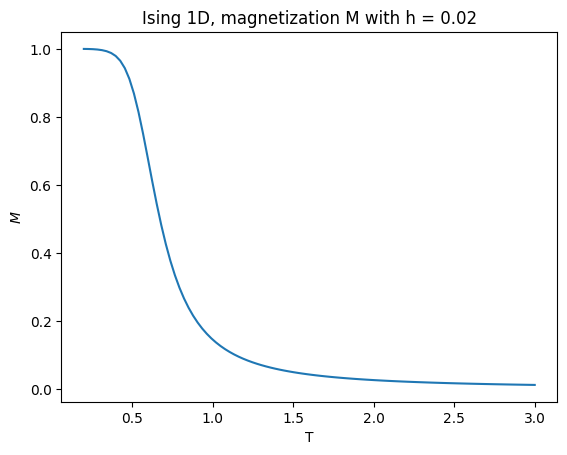

In [3]:
h=0.02 #external field
b = 1/T

l1 = np.exp(b*J)*np.cosh(b*h)+np.sqrt(np.exp(2*b*J)*np.cosh(b*h)*np.cosh(b*h)-2*np.sinh(2*b*J))
l2 = np.exp(b*J)*np.cosh(b*h)-np.sqrt(np.exp(2*b*J)*np.cosh(b*h)*np.cosh(b*h)-2*np.sinh(2*b*J))
Z = l1**Ns + l2**Ns
M = (np.exp(b*J)*np.sinh(b*h)*((l1**(Ns-1))*(1+np.exp(b*J)*np.cosh(b*h)/np.sqrt(np.exp(2*b*J)*np.cosh(b*h)*np.cosh(b*h)-2*np.sinh(2*b*J))) 
        + (l2**(Ns-1))*(1-np.exp(b*J)*np.cosh(b*h)/np.sqrt(np.exp(2*b*J)*np.cosh(b*h)*np.cosh(b*h)-2*np.sinh(2*b*J)))))/(Z)
plt.plot(T, M)
plt.title('Ising 1D, magnetization M with h = 0.02')
plt.xlabel('T')
plt.ylabel('$M$')
plt.show()

- The **magnetic susceptibility** (with $h=0$):

$$
\chi(N,T) = \frac{\partial M}{\partial h} = 
\frac{\partial}{\partial h}\sum_{\{ s_i \}} \left[ \sum_{i=1,N}s_i\right] \frac{\exp \left( -\beta H\right)}{Z} =\\
= \beta\sum_{\{ s_i \}} \left[ \sum_{i=1,N}s_i\right]^2 \frac{\exp \left( -\beta H\right)}{Z}
-\sum_{\{ s_i \}} \left[ \sum_{i=1,N}s_i\right] \frac{\exp \left( -\beta H\right)}{Z}
\frac{1}{Z}\frac{\partial Z}{\partial h} = 
\beta \left[ \left\langle \left( \sum_{i=1,N}s_i \right)^2 \right\rangle - \left\langle \sum_{i=1,N}s_i \right\rangle^2 \right] = \\
\underset{h=0}= \beta \left[ \left\langle \left( \sum_{i=1,N}s_i \right)^2 \right\rangle \right] = \beta e^{2\beta J} \Biggl( \frac{1-\tanh^N (\beta J)}{1+\tanh^N (\beta J)} \Biggl)
$$

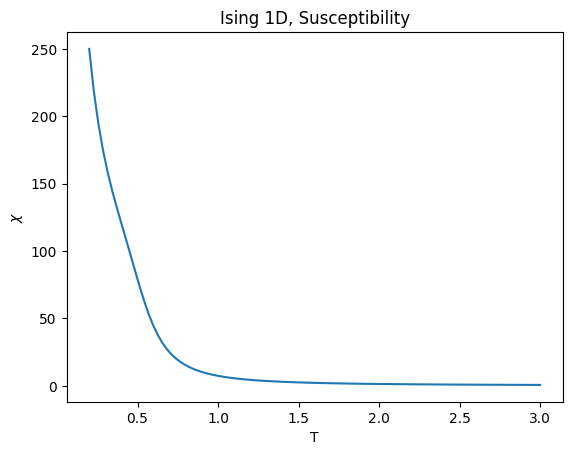

In [4]:
X = beta*np.exp(2*beta*J)*(1-thN)/(1+thN)
plt.plot(T, X)
plt.title('Ising 1D, Susceptibility')
plt.xlabel('T')
plt.ylabel('$\chi$')
plt.show()

Diverge per T --> 0

### Exercise 06.1

Complete the NSL_simulator code to simulate a 1D Ising model with the Gibbs sampling algorithm (the Metropolis algorithm is already implemented) to sample the Boltzmann's weight $p(\{ s_i \}) = \exp(-\beta H)/Z$. Verify the possibility to restart from a previous spin configuration.

The code already computes the internal energy: $U(N,T) = \langle H \rangle$. Add the calculation of $C(N,T)$, $\chi(N,T)$, $M(N,T,h)$ and compute:
1. $U(N,T) = \langle H \rangle_{h=0}$
2. $C(N,T) = k_B \beta^2 (\langle H^2 \rangle_{h=0}-\langle H \rangle_{h=0}^2)$ 
3. $\chi(N,T) = \beta \langle (\sum_{i=1,N}s_i)^2 \rangle_{h=0}$
4. $M(N,T,h=0.02)= \langle \sum_{i=1,N}s_i \rangle_{h=0.02}$

as a function of $T$ in the range $\left[0.5;2.0\right]$ for a system of $N=50$ spins with $J=1$.

As usual, use data blocking and give an estimate of the statistical uncertainties.

- <span style="color:red">Show pictures of your estimations of $U(N,T)$, $C(N,T)$, $\chi(N,T)$, $M(N,T,h=0.02)$ and their uncertainties</span> obtained with a large number of *MC steps* (e.g. $M\ge 10^5$) compared with the exact curves. In the same picture show your results obtained with <span style="color:blue">both sampling methods, Metropolis and Gibbs</span>.

A Monte Carlo step will consist in trying to flip one time all the spins of the system. Do not forget to equilibrate your simulations and to use blocking average with blocks large enough.

# <span style="color:green"> RESULTS: </span>

In this notebook we will simulate a one-dimensional Ising model, study its main thermodynamic quantities and then compare them with the exact solutions, obtained analytically through the partition function $Z$.

### The 1D Ising model
The Ising model describes a system of $N$ spins $s_i=\pm1$ placed on a lattice, interacting with their nearest neighbours and with an external magnetic field $h$. In one dimension, with periodic boundary conditions ($s_{N+1}=s_1$), the Hamiltonian is:
$$
H = -J\sum_{i=1}^N s_i s_{i+1} -\frac{h}{2}\sum_{i=1}^N (s_i + s_{i+1}) $$
where $J>0$ is the ferromagnetic coupling term: which tells that neighbouring spins prefer to be aligned. We use units with $k_B=1$ and $J=1$, so the temperature is measured in units of $J/k_B$. The model describes a magnetic material and its interaction with a magnetic field, and in one dimension it can be solved exactly with the transfer matrix method. The partition function is:
$$Z = \lambda_1^N + \lambda_2^N, \qquad \lambda_{1,2} = e^{\beta J}\cosh(\beta h) \pm \sqrt{e^{2\beta J}\sinh^2(\beta h) + e^{-2\beta J}}$$
and all the thermodynamic quantities follow from its derivatives. Moreover in one dimension there is no phase transition at finite temperature: the system is disordered for every $T>0$, while the correlation length grows as $T\to0$.

### Thermodynamic quantities
We analyzed four quantities per spin: internal energy, specific heat, magnetic susceptibility and magnetization. In the simulation they are estimated as:
$$\frac{U}{N}=\frac{\langle H\rangle}{N}, \qquad C=\frac{\langle H^2\rangle-\langle H\rangle^2}{N\,T^2}, \qquad \chi=\frac{\langle M^2\rangle-\langle M\rangle^2}{N\,T}, \qquad m=\frac{\langle M\rangle}{N}$$
where $M=\sum_i s_i$ is the total magnetization. The exact solution gives the corresponding total quantities as derivatives of $Z$:
$$U=-\frac{\partial \ln Z}{\partial\beta}, \qquad C=\frac{\partial U}{\partial T}, \qquad M=\frac1\beta\,\frac{\partial \ln Z}{\partial h}, \qquad \chi=\frac{\partial M}{\partial h}$$
which must be divided by $N$ to be compared with the simulation. For $U$, $C$ and $\chi$ we used $h=0$, while the magnetization is non-zero only for $h\neq0$, so $m$ was measured with a small field $h=0.02$.

These quantities are computed in the functions <small><code>measure()</code></small> and <small><code>averages()</code></small>: the first stores the values at each step of a block, the second performs the data blocking. The internal energy was already implemented, and the magnetization and the susceptibility follow a similar implementation. At $h=0$ we have $\langle M\rangle=0$, so $\chi=\beta\langle M^2\rangle/N$ and only $M^2$ needs to be stored:
<small>
```cpp
// in measure():
if (_measure_magnet){
    double m = 0.0;
    for (int i=0; i<_npart; i++) m += double(_particle(i).getspin());
    _measurement(_index_magnet) = m/double(_npart);
}
if (_measure_chi){
    double m = 0.0;
    for (int i=0; i<_npart; i++) m += double(_particle(i).getspin());
    _measurement(_index_chi) = _beta * (m*m) / double(_npart);
}

// in averages():
if (_measure_magnet){
    coutf.open("../OUTPUT/magnetization.dat", ios::app);
    average     = _average(_index_magnet);
    sum_average = _global_av(_index_magnet);
    sum_ave2    = _global_av2(_index_magnet);
    coutf << setw(12) << blk
          << setw(12) << average
          << setw(12) << sum_average/double(blk)
          << setw(12) << this->error(sum_average, sum_ave2, blk) << endl;
    coutf.close();
}
if (_measure_chi){
    coutf.open("../OUTPUT/susceptibility.dat", ios::app);
    average     = _average(_index_chi);
    sum_average = _global_av(_index_chi);
    sum_ave2    = _global_av2(_index_chi);
    coutf << setw(12) << blk
          << setw(12) << average
          << setw(12) << sum_average/double(blk)
          << setw(12) << this->error(sum_average, sum_ave2, blk) << endl;
    coutf.close();
}
```
</small>

The specific heat is different, because it depends on the energy fluctuations and is therefore not the average of a single-step quantity. In <small><code>measure()</code></small> we store only $H^2$ at each step. The variance is then computed inside each block, before the global accumulation, in <small><code>average()</code></small>: the block average of $H^2$ and the square of the block average of $H$ give $C=\beta^2(\langle H^2\rangle-\langle H\rangle^2)/N$ for that block. The blocks are then averaged as for the other quantities.
<small>
```cpp
// in measure():
if (_measure_cv){
    double s_i, s_j;
    double h = 0.0;                                    // total energy of the configuration
    for (int i=0; i<_npart; i++){
        s_i = double(_particle(i).getspin());
        s_j = double(_particle(this->pbc(i+1)).getspin());
        h += - _J * s_i * s_j - 0.5 * _H * (s_i + s_j);
    }
    _measurement(_index_cv) = h*h;
    // C_V = ( <H^2> - <H>^2 ) / (k_B T^2): a variance cannot be evaluated at a single step,
    // so we store H^2 and compute the variance in the data blocking phase
}

// in average():
_average = _block_av / double(_nsteps);
// compute C_V of the block BEFORE the global accumulation, overwriting _average(_index_cv)
if (_measure_cv){
    double ave_h  = _average(_index_tenergy) * _npart;   // <H>   in this block
    double ave_h2 = _average(_index_cv);                 // <H^2> in this block
    _average(_index_cv) = _beta * _beta * (ave_h2 - ave_h * ave_h) / double(_npart);
}
_global_av  += _average;
_global_av2 += _average % _average;
...
if (_measure_cv){
    coutf.open("../OUTPUT/specific_heat.dat", ios::app);
    double cv_block    = _average(_index_cv);
    double sum_avg_cv  = _global_av(_index_cv);
    double sum_avg2_cv = _global_av2(_index_cv);
    coutf << setw(12) << blk
          << setw(12) << cv_block
          << setw(12) << sum_avg_cv / double(blk)
          << setw(12) << this->error(sum_avg_cv, sum_avg2_cv, blk) << endl;
    coutf.close();
}
```
</small>

To compare the quantities with the exact values we simulated the system at different temperatures and, for each temperature, we took the final mean of the data blocking method together with its statistical error.

The parameters used in the simulation are $N=50$ spins and 16 equally spaced temperatures in $T\in[0.5,2]$ ($\Delta T=0.1$). The simulation was run from the highest temperature to the lowest, and each temperature starts from the final configuration of the previous one, with this method the system is already close to equilibrium at the beginning of every run, so the equilibration problems and time are reduced. At each temperature the system is first equilibrated for $n_{eq}=5000$ steps (not included in the measurements) and then measured in 20 blocks of $2\cdot10^4$ steps each. $U$, $C$ and $\chi$ were measured at $h=0$, and $m$ at $h=0.02$.

### Sampling methods
To sample the Boltzmann distribution $p(\{s_i\})\propto e^{-\beta H}$ we used two different Markov chain Monte Carlo methods, and we then compared them.

#### Metropolis sampling
A spin $s_k$ is chosen and a flip $s_k\to-s_k$ is proposed. The move changes the energy by
$$\Delta E = 2 s_k\left[J\,(s_{k-1}+s_{k+1}) + h\right]$$
and is accepted with probability $P=\min\left(1,e^{-\beta\Delta E}\right)$, moves that lower the energy are always accepted, the others with a Boltzmann probability. If the move is rejected, the old configuration is counted again.
<small>
```cpp
bool System :: metro(int i){ // Metropolis algorithm
    bool decision = false;
    double delta_E, acceptance;
    if(_sim_type == 1) delta_E = this->Boltzmann(i,true) - this->Boltzmann(i,false);
    else delta_E = 2.0 * _particle(i).getspin() *
                   ( _J * (_particle(this->pbc(i-1)).getspin() + _particle(this->pbc(i+1)).getspin() ) + _H );
    acceptance = exp(-_beta*delta_E);
    if(_rnd.Rannyu() < acceptance ) decision = true; // Metropolis acceptance step
    return decision;
}
```
</small>

#### Gibbs sampling
In Gibbs sampling a spin $s_k$ is chosen and it is assigned a new value, drawn from its conditional distribution given all the other spins. Since $s_k$ interacts only with its two neighbours, we get
$$P(s_k=+1) = \frac{1}{1+e^{-2\beta\left[J(s_{k-1}+s_{k+1})+h\right]}}, \qquad P(s_k=-1)=1-P(s_k=+1)$$
The new value does not depend on the old one, so there are no rejected moves: every proposal is accepted.
<small>
```cpp
if(_sim_type == 3){ // Gibbs sampler for Ising
    // effective field on spin i: neighbours + external field
    // (the energy difference between the states s=+1 and s=-1 is -2*h_eff)
    double h_eff = _J * (_particle(this->pbc(i-1)).getspin() + _particle(this->pbc(i+1)).getspin()) + _H;

    // probability of spin = +1: P = 1 / (1 + exp(-2 * beta * h_eff))
    double prob_plus = 1.0 / (1.0 + exp(-2.0 * _beta * h_eff));

    // draw a random number and assign the spin
    if(_rnd.Rannyu() < prob_plus) _particle(i).setspin(1);
    else                          _particle(i).setspin(-1);
    _naccepted++; // Gibbs: the move is always "accepted" (a new value is drawn)
}
```
</small>

In both algorithms the sequence of configurations $s^{(0)}, s^{(1)}, s^{(2)},\dots$ is a Markov chain on the $2^N$ spin configurations: the probability of the next configuration depends only on the current one, not on the previous history. If $s'$ differs from $s$ only in the spin $k$, chosen at random among the $N$ spins, the transition probabilities are
$$T_{\rm Metropolis}(s\to s')=\frac1N\min\left(1,e^{-\beta\Delta E}\right), \qquad T_{\rm Gibbs}(s\to s')=\frac1N\,\frac{1}{1+e^{\beta\Delta E}}$$
with $\Delta E=H(s')-H(s)$, and with the remaining probability the system stays in $s$. Both satisfy detailed balance with respect to the Boltzmann distribution $\pi(s)\propto e^{-\beta H(s)}$,
$$\pi(s)\,T(s\to s')=\pi(s')\,T(s'\to s)$$
so $\pi$ is a stationary distribution of the chain. The chain is also irreducible as any configuration can be reached by flipping one spin at a time, with positive probability at finite $T$; and aperiodic as the probability of staying in the same configuration is positive. Therefore, for any initial configuration, the distribution of the chain converges to the Boltzmann one and time averages converge to ensemble averages, so the two algorithms must give the same averages.

This has two consequences. First, the chain converges to the Boltzmann distribution only asymptotically, so an initial equilibration is needed before the measurements: starting from an arbitrary configuration, the system was equilibrated for $n_{eq}=5000$ steps, which are not included in the blocks. Second, consecutive configurations are correlated, so the statistical uncertainty is computed with the data blocking method, using blocks longer than the autocorrelation time.

In [5]:
load = lambda name: np.loadtxt(f"OUTPUT_final/final_{name}.dat")
data = {m: (load(f"{m}_h0"), load(f"{m}_h002")) for m in ("metropolis", "gibbs")}

In [6]:
# dictionary method: (label, marker, color)
style = {"metropolis": ("Metropolis", "o", '#109e28'),
         "gibbs": ("Gibbs", "o", '#0c459a')}

# Observables: (title, y-label, exact curve, file index [0: h=0, 1: h=0.02], column of the value)
obs = [("Internal Energy $U/N$ ($h=0$)",  "$U/N$", e, 0, 1),
       ("Heat Capacity $C$ ($h=0$)",  "$C$", heat, 0, 3),
       ("Magnetic Susceptibility $\\chi$ ($h=0$)", "$\\chi$", X, 0, 5),
       ("Magnetization $M/N$ ($h=0.02$)", "$M/N$",  M,  1, 1)]

In [7]:
def plot_ising(methods, suptitle):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(suptitle, fontsize=16)
    for ax, (title, ylabel, exact, f, c) in zip(axes.flatten(), obs):
        ax.plot(T, exact, color='black', lw=1, label='Exact Theory')   
        for m in methods:
            label, fmt, color = style[m]
            d = data[m][f]                                        
            ax.errorbar(d[:, 0], d[:, c], yerr=d[:, c + 1], fmt=fmt, ms=4, color=color,capsize=3, elinewidth=1, zorder=3, label=label)  
        ax.set_title(title)
        ax.set_xlabel('Temperature $T$'); ax.set_ylabel(ylabel)
        ax.grid(True, ls=':', alpha=0.6); ax.legend()
    plt.tight_layout()
    plt.show()

The following figures shows the data obtained with the Metropolis sampling and Gibbs sampling, compared with the exact solution for $N=50$:

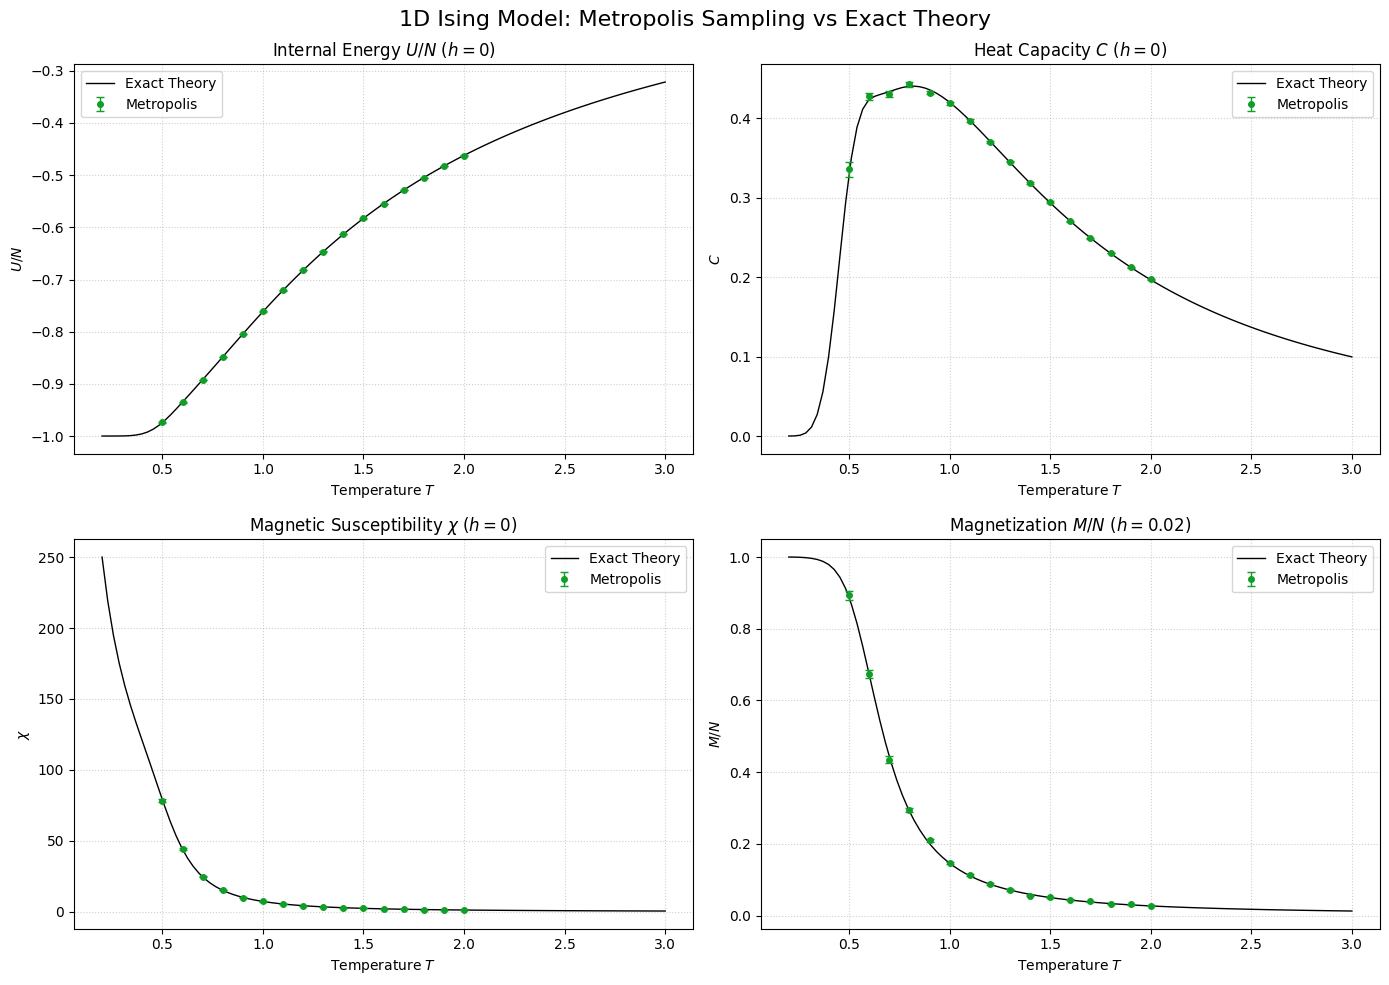

In [8]:
plot_ising(["metropolis"],'1D Ising Model: Metropolis Sampling vs Exact Theory')

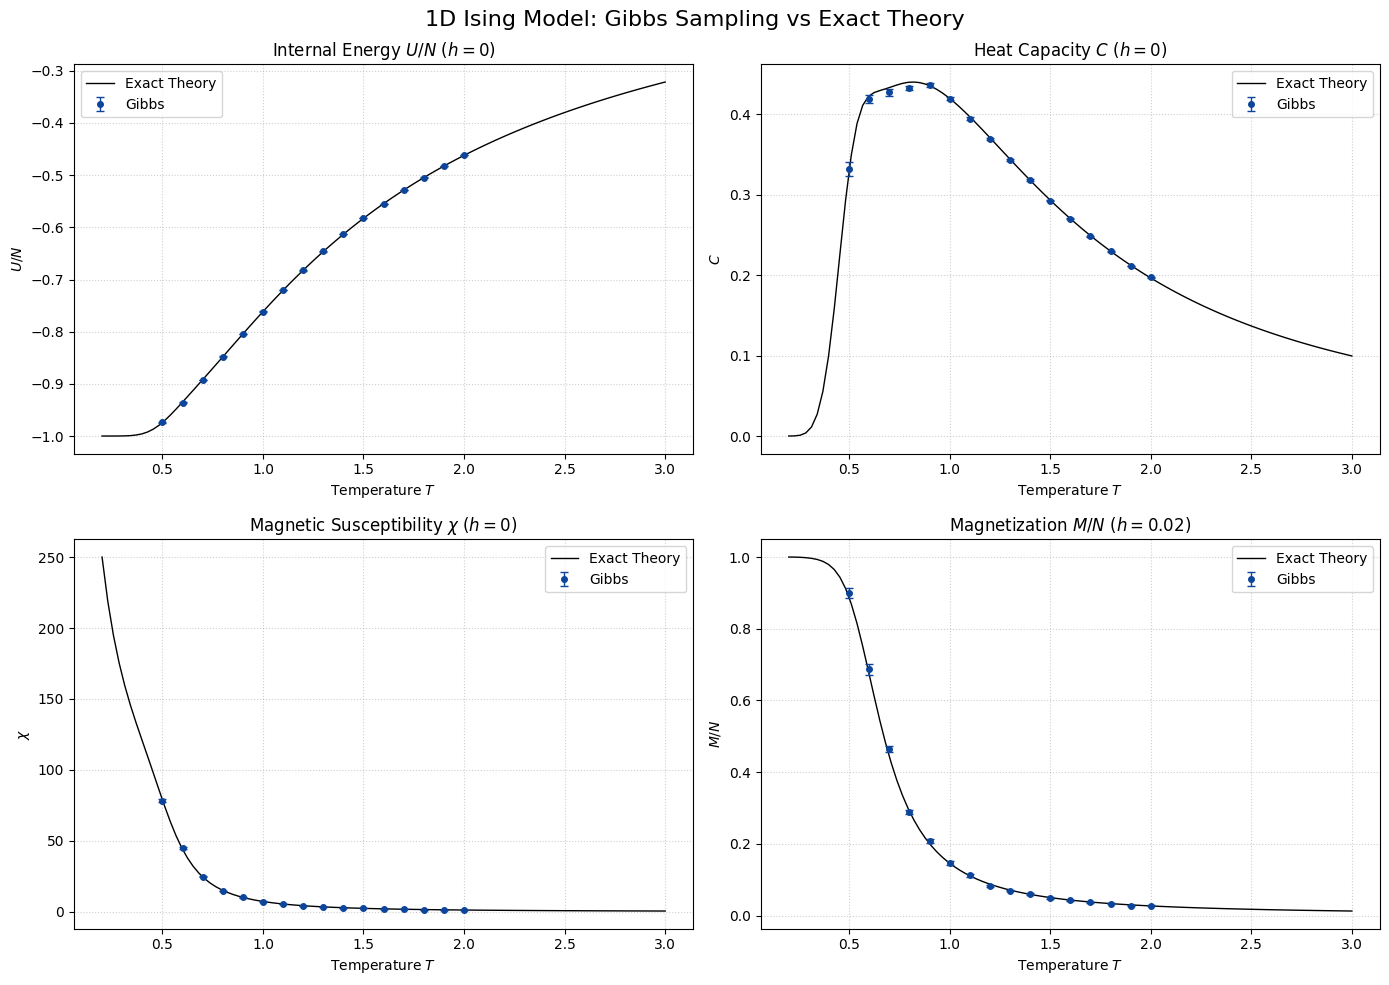

In [9]:
plot_ising(["gibbs"],'1D Ising Model: Gibbs Sampling vs Exact Theory')

Both sampling methods reproduce the exact solution for $N=50$ within the statistical uncertainty, for all four quantities and over the whole temperature range shown in the plots. The error bars are barely visible, except at low temperature for the specific heat and the magnetization.

The behaviour of the four quantities is the one expected for a one-dimensional system with no phase transition:

The internal energy $U/N$ goes smoothly from $-J$ at low temperature, where all the spins are aligned with their neighbours, towards $0$ at high temperature, where the thermal agitation dominates. The curve has no singularity.

The specific heat $C$ shows a broad maximum at intermediate temperature and then decreases on both sides. It does not diverge: the peak is due to the thermal excitation of domain walls, which cost an energy $2J$, and not to a phase transition.

The susceptibility $\chi$ increases rapidly when $T$ decreases, because the correlation length grows and larger and larger groups of spins respond together to the field. It stays finite for every $T>0$ (for finite $N$ it is limited by the size of the chain), so there is no spontaneous magnetization.

The magnetization $m$, computed with a small field $h=0.02$, is large at low temperature: the domains are so long that even a small field aligns them. It then decreases towards zero as $T$ increases, where the field becomes too weak compared to the thermal agitation. At $h=0$ we would have $m=0$ for every $T>0$.

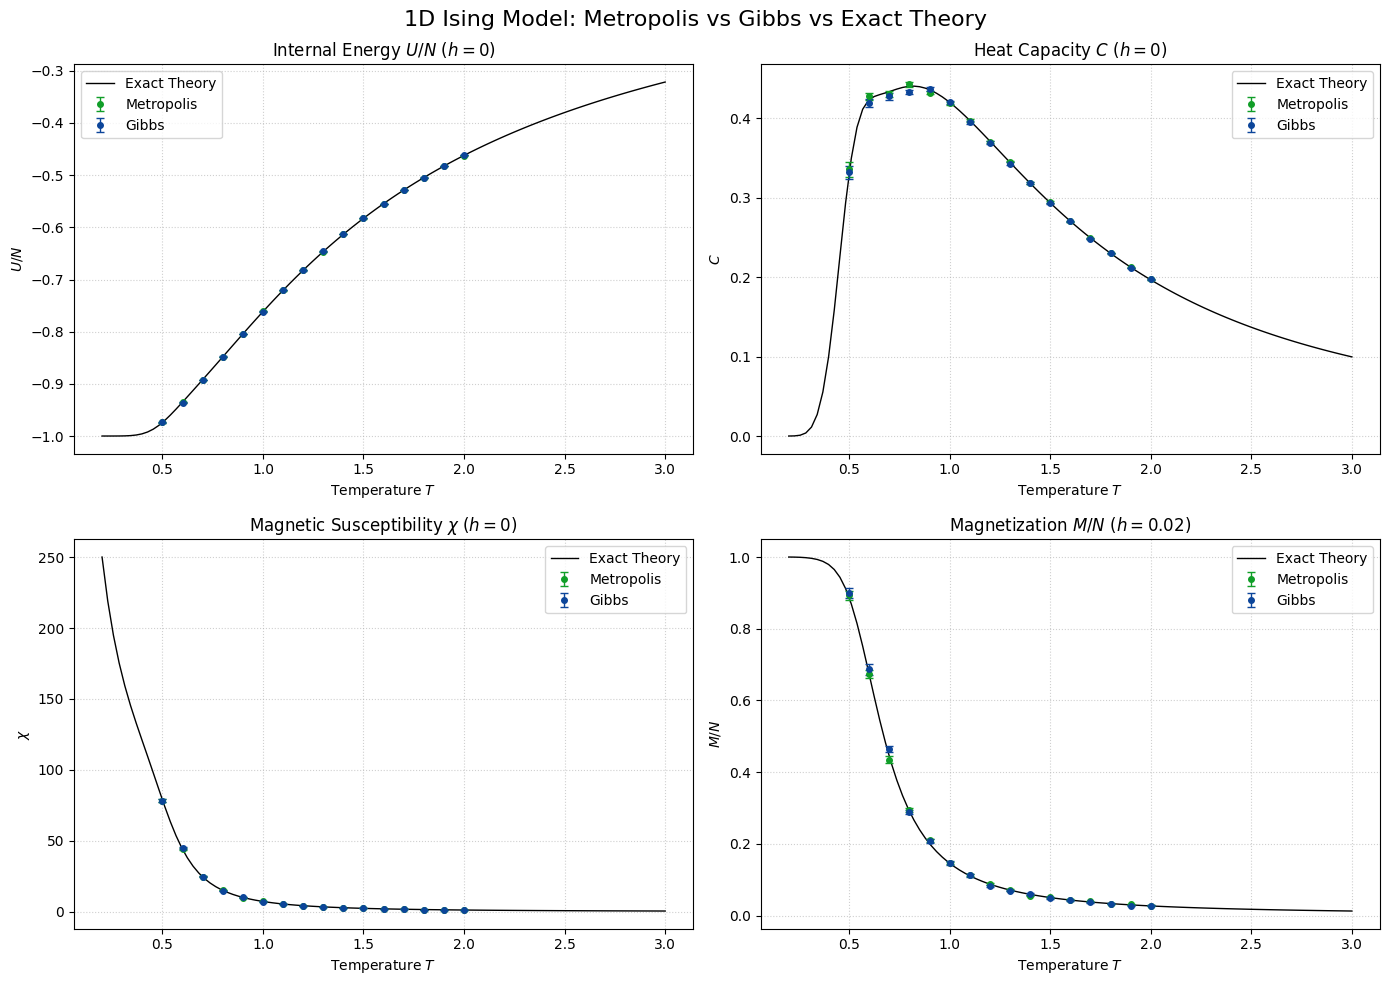

In [10]:
plot_ising(["metropolis", "gibbs"],  '1D Ising Model: Metropolis vs Gibbs vs Exact Theory')

As expected both methods give results that are compatible with each other and with the exact solution, since they sample the same Boltzmann distribution. The difference is in the statistical errors. 

To compare them we use the ratio $r=\sigma_{Gibbs}/\sigma_{Metropolis}$ between the errors obtained with the same number of steps. Averaged over the 16 temperatures, $r$ is $1.19$ for $U/N$, $1.05$ for $C$, $1.15$ for $\chi$ and $1.27$ for $m$. Metropolis therefore has a smaller error, by about 15% overall, except for $C$, where the two methods are equivalent within the uncertainty. Since the error decreases as $1/\sqrt{n_{steps}}$, Gibbs needs about $1.35$ times more steps than Metropolis to reach the same precision. 

For both methods the absolute errors grow when the temperature decreases, because the fluctuations and the correlation length of the system increase. 

We did not measure the CPU time. We assume that the cost of one step is similar in the two algorithms (both compute the local field and use one random number and one exponential), so the comparison at equal number of steps should also hold at equal cost.